# Telco Customer Churn: Master Notebook (Week 1, Tân's tasks)

**Owner of this file:** Tân (Lead Pipeline & Explainability) · **Course:** Statistical Learning · **Dataset:** Telco Customer Churn (7,043 customers, 21 columns)

This notebook covers Tân's Week 1 tasks only. Everything the team shares (constants, cleaning rules, the 80/20 split, the preprocessing recipe, metric helpers) is defined **once, in Section 1**. There is no separate `churn_core.py`: every cell below Section 1 can use those names directly, and Yến and NMinh can append their sections to the end of this file.

| Section | Content | Task in the tracker PDF |
|---|---|---|
| 1 | Shared toolkit | shared by all |
| 2 and 3 | Raw-data audit and deterministic cleaning | Task 1.2 |
| 4 | Stratified 80/20 split | needed here so EDA can use the train set only |
| 5 | Descriptive statistics, boxplots, churn distribution, Chi-square and Cramér's V (train only) | Task 1.3 |

Run with **Kernel → Restart & Run All**.

## 1. Shared toolkit

Section 1 is split into five cells: imports and paths, cleaning, the split, the preprocessing pipeline, and metric helpers. The last two are not used in this notebook; they are included so teammates can use them. Nothing here depends on the data being loaded yet, so the whole section only defines names.

**Where the files go.** The notebook looks for the raw CSV in `data/raw/telco_customer_churn.csv`, then next to the notebook (`telco_customer_churn.csv` or the original Kaggle name `WA_Fn-UseC_-Telco-Customer-Churn.csv`). Outputs are written to `data/processed/`, `artifacts/` and `reports/figures/`, which are created automatically.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "telco_customer_churn.csv",
    PROJECT_ROOT / "telco_customer_churn.csv",
    PROJECT_ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
RAW_DATA_PATH = next((path for path in RAW_DATA_CANDIDATES if path.exists()), None)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, ARTIFACTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_CV_FOLDS = 5
SIGNIFICANCE_LEVEL = 0.05

ID_COLUMN = "customerID"
TARGET_COLUMN = "Churn"
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
INTERNET_DEPENDENT_FEATURES = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
def load_raw_customers(path=RAW_DATA_PATH):
    """Read the original CSV without changing anything."""
    if path is None:
        searched = "\n".join(str(candidate) for candidate in RAW_DATA_CANDIDATES)
        raise FileNotFoundError(f"Raw CSV not found. Put it in one of:\n{searched}")
    return pd.read_csv(path)


def clean_customers(customers_raw):
    """Return a cleaned copy indexed by customerID.

    Rules fixed by business logic (not estimated from data), so applying them
    before the split cannot leak test information: strip whitespace, convert
    TotalCharges to float, set the blank TotalCharges of never-billed customers
    (tenure == 0) to 0, and merge "No internet service" / "No phone service" into "No".
    """
    if customers_raw[ID_COLUMN].duplicated().any():
        raise ValueError("customerID must be unique.")

    customers = customers_raw.copy()
    for column in customers.select_dtypes(exclude="number").columns:
        customers[column] = customers[column].str.strip()

    total_charges_is_blank = customers["TotalCharges"].eq("")
    customer_never_billed = customers["tenure"].eq(0)
    if not total_charges_is_blank.equals(customer_never_billed):
        raise ValueError("Blank TotalCharges no longer matches tenure == 0.")

    total_charges = pd.to_numeric(
        customers["TotalCharges"].where(~total_charges_is_blank), errors="raise"
    )
    customers["TotalCharges"] = total_charges.fillna(0.0).astype("float64")

    merge_redundant_service_labels(customers)
    return customers.set_index(ID_COLUMN)


def merge_redundant_service_labels(customers):
    """Replace "No internet service" / "No phone service" by "No", in place."""
    redundant_label_rules = [
        (INTERNET_DEPENDENT_FEATURES, "No internet service", customers["InternetService"].eq("No")),
        (["MultipleLines"], "No phone service", customers["PhoneService"].eq("No")),
    ]
    for columns, redundant_label, implied_by_other_column in redundant_label_rules:
        for column in columns:
            if not customers[column].eq(redundant_label).equals(implied_by_other_column):
                raise ValueError(f"'{redundant_label}' in {column} is not fully implied by another column.")
            customers[column] = customers[column].replace(redundant_label, "No")

In [3]:
def split_train_test(customers):
    """Stratified 80/20 split shared by the whole team.

    Returns X_train, X_test, y_train, y_test where y is 1 for churn, 0 otherwise.
    """
    features = customers[ALL_FEATURES]
    target = customers[TARGET_COLUMN].map({"No": 0, "Yes": 1}).astype("int64")
    return train_test_split(
        features, target,
        test_size=TEST_SIZE, stratify=target, random_state=RANDOM_STATE,
    )

In [4]:
def build_preprocessor():
    """Unfitted ColumnTransformer: scale numeric, one-hot encode categorical.

    Always place it inside a Pipeline so fit() only sees training data,
    including inside every cross-validation fold.
    """
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return preprocessor.set_output(transform="pandas")


def build_model_pipeline(estimator):
    """Preprocessing + estimator as one object, ready for fit/predict/GridSearchCV."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])


def get_feature_names(fitted_pipeline):
    """Column names produced by the fitted preprocessing step."""
    return list(fitted_pipeline.named_steps["preprocess"].get_feature_names_out())

In [5]:
def compute_basic_metrics(y_true, y_pred):
    """Accuracy and churn-class (label 1) precision, recall, F1."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def make_logistic_regression(penalty, C=1.0):
    """L1 or L2 logistic regression that runs without warnings on scikit-learn 1.2+.

    scikit-learn 1.8 replaced `penalty` with `l1_ratio` (1.0 means L1, 0.0 means L2).
    liblinear supports both penalties on this small dataset.
    """
    if penalty not in ("l1", "l2"):
        raise ValueError("penalty must be 'l1' or 'l2'.")
    if SKLEARN_VERSION >= (1, 8):
        penalty_settings = {"l1_ratio": 1.0 if penalty == "l1" else 0.0}
    else:
        penalty_settings = {"penalty": penalty}
    return LogisticRegression(
        C=C, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **penalty_settings
    )

## 2. Load and audit the raw data

The raw file is loaded untouched first. The audit looks for problems that `isna()` alone cannot see: blank strings, duplicates, inconsistent labels and impossible values. Each finding either justifies a cleaning rule or is recorded as "checked, nothing to do".

In [6]:
customers_raw = load_raw_customers()
print(f"Rows: {customers_raw.shape[0]:,} | Columns: {customers_raw.shape[1]}")
customers_raw.head()

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [7]:
customers_raw.dtypes.to_frame("raw_dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
raw_dtype,object,object,int64,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,float64,object,object


`TotalCharges` is stored as text although it holds money amounts, so it must contain at least one non-numeric entry. The next cell counts missing values in two ways: real `NaN` and blank text.

In [8]:
text_columns = customers_raw.select_dtypes(exclude="number")
missing_overview = pd.DataFrame({
    "nan_count": customers_raw.isna().sum(),
    "blank_text_count": text_columns.apply(lambda column: column.str.strip().eq("").sum()),
}).fillna(0).astype(int)
missing_overview[missing_overview.sum(axis=1) > 0]

,nan_count,blank_text_count
TotalCharges,0,11


`isna()` reports no missing values, yet 11 `TotalCharges` cells are blank text. Here are those customers.

In [9]:
blank_total_charges = customers_raw[customers_raw["TotalCharges"].str.strip().eq("")]
display(blank_total_charges[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

print("Every blank row has tenure == 0:", blank_total_charges["tenure"].eq(0).all())
print("Rows with tenure == 0 in the whole dataset:", customers_raw["tenure"].eq(0).sum())
print("Churn labels among blank rows:", blank_total_charges["Churn"].value_counts().to_dict())

,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.5500,,Two year,No
753,0,20.2500,,Two year,No
936,0,80.8500,,Two year,No
1082,0,25.7500,,Two year,No
1340,0,56.0500,,Two year,No
3331,0,19.8500,,Two year,No
3826,0,25.3500,,Two year,No
4380,0,20.0000,,Two year,No
5218,0,19.7000,,One year,No
6670,0,73.3500,,Two year,No


Every blank row has tenure == 0: True
Rows with tenure == 0 in the whole dataset: 11
Churn labels among blank rows: {'No': 11}


**Finding.** The 11 blank cells are exactly the 11 customers with `tenure == 0`. They have just signed up and have not received a first bill, so the true total charged is 0. Setting `TotalCharges = 0` is therefore a factual correction rather than an estimate, and it needs no statistics from the data. That is why it is safe to apply before the train/test split.

In [10]:
duplicated_ids = customers_raw["customerID"].duplicated().sum()
rows_identical_except_id = customers_raw.drop(columns="customerID").duplicated().sum()
print("Duplicated customerID:", duplicated_ids)
print("Rows identical in every column except customerID:", rows_identical_except_id)

Duplicated customerID: 0
Rows identical in every column except customerID: 22


Customer IDs are unique, so no customer appears twice. A small number of different customers share an identical profile, which is expected when 16 of 19 features are categorical. These rows are kept.

In [11]:
for column in CATEGORICAL_FEATURES:
    print(f"{column:<18}", sorted(customers_raw[column].unique()))
customers_raw[["tenure", "MonthlyCharges"]].describe()

gender             ['Female', 'Male']
SeniorCitizen      [np.int64(0), np.int64(1)]
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


,tenure,MonthlyCharges
count,7043.0000,7043.0000
mean,32.3711,64.7617
std,24.5595,30.0900
min,0.0000,18.2500
25%,9.0000,35.5000
50%,29.0000,70.3500
75%,55.0000,89.8500
max,72.0000,118.7500


Labels are spelled consistently (no case or spacing variants), `SeniorCitizen` is strictly 0/1, `tenure` is within 0 to 72 months and `MonthlyCharges` is positive. The last structural check confirms that the "No internet service" and "No phone service" labels appear exactly when they logically must. If they do, they carry no information beyond `InternetService == "No"` and `PhoneService == "No"`.

In [12]:
internet_dependent_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
has_no_internet = customers_raw["InternetService"].eq("No")
has_no_phone = customers_raw["PhoneService"].eq("No")

consistency_checks = {
    f"{column}: 'No internet service' iff InternetService == 'No'":
        customers_raw[column].eq("No internet service").equals(has_no_internet)
    for column in internet_dependent_columns
}
consistency_checks["MultipleLines: 'No phone service' iff PhoneService == 'No'"] = (
    customers_raw["MultipleLines"].eq("No phone service").equals(has_no_phone)
)
consistency_checks["SeniorCitizen only contains 0 and 1"] = set(customers_raw["SeniorCitizen"]) == {0, 1}
consistency_checks["tenure within 0..72"] = customers_raw["tenure"].between(0, 72).all()
consistency_checks["MonthlyCharges > 0"] = customers_raw["MonthlyCharges"].gt(0).all()

pd.Series(consistency_checks, name="passed").to_frame()

,passed
OnlineSecurity: 'No internet service' iff InternetService == 'No',True
OnlineBackup: 'No internet service' iff InternetService == 'No',True
DeviceProtection: 'No internet service' iff InternetService == 'No',True
TechSupport: 'No internet service' iff InternetService == 'No',True
StreamingTV: 'No internet service' iff InternetService == 'No',True
StreamingMovies: 'No internet service' iff InternetService == 'No',True
MultipleLines: 'No phone service' iff PhoneService == 'No',True
SeniorCitizen only contains 0 and 1,True
tenure within 0..72,True
MonthlyCharges > 0,True


In [13]:
assert all(consistency_checks.values())

total_charges_numeric = pd.to_numeric(customers_raw["TotalCharges"], errors="coerce")
billed_customers = customers_raw["tenure"].gt(0)
expected_total = customers_raw["tenure"] * customers_raw["MonthlyCharges"]
relative_gap = ((total_charges_numeric - expected_total).abs() / expected_total)[billed_customers]
relative_gap.describe(percentiles=[0.5, 0.95]).to_frame("|TotalCharges - tenure x MonthlyCharges| / expected")

,|TotalCharges - tenure x MonthlyCharges| / expected
count,7032.0000
mean,0.0320
std,0.0399
min,0.0000
50%,0.0200
95%,0.1032
max,0.5735


`TotalCharges` is close to `tenure × MonthlyCharges` for most customers (median gap about 2%), with larger gaps for customers whose price changed over time. This means `TotalCharges` is largely a product of the other two numeric features, so strong correlation among them is expected. It matters later when coefficients are interpreted.

## 3. Clean the data (tracker Task 1.2)

`clean_customers()` (Section 1) performs four steps:

1. Strip stray whitespace from text columns.
2. Convert `TotalCharges` to `float` and fill the 11 blanks with 0.
3. Merge "No internet service" and "No phone service" into "No" in the 7 dependent service columns. The audit proved these labels only repeat `InternetService == "No"` and `PhoneService == "No"`. Left in place, the six internet-service columns would become identical dummy columns, and a regression would split their effect between them arbitrarily.
4. Use `customerID` as the row index, so any row can be traced back to a customer (needed later for SHAP waterfall plots).

The function raises an error if the blank cells stop matching `tenure == 0` or if a redundant label is not fully implied by another column, so a changed dataset cannot be cleaned silently.

In [14]:
customers = clean_customers(customers_raw)

assert len(customers) == len(customers_raw)
assert customers["TotalCharges"].dtype == "float64"
assert customers.isna().sum().sum() == 0
assert customers.loc[customers["tenure"].eq(0), "TotalCharges"].eq(0).all()
assert all(customers[column].nunique() == 2 for column in INTERNET_DEPENDENT_FEATURES + ["MultipleLines"])

cleaning_summary = pd.DataFrame({
    "before": {
        "TotalCharges dtype": str(customers_raw["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers_raw["TotalCharges"].str.strip().eq("").sum()),
        "rows": len(customers_raw),
        "labels in OnlineSecurity": customers_raw["OnlineSecurity"].nunique(),
    },
    "after": {
        "TotalCharges dtype": str(customers["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers["TotalCharges"].isna().sum()),
        "rows": len(customers),
        "labels in OnlineSecurity": customers["OnlineSecurity"].nunique(),
    },
})
cleaning_summary

,before,after
TotalCharges dtype,object,float64
blank TotalCharges cells,11,0
rows,7043,7043
labels in OnlineSecurity,3,2


## 4. Stratified train/test split

The target is imbalanced (about 26.5% churn), so a random split could shift that ratio and the split must be stratified. `split_train_test()` uses `test_size=0.20`, `stratify=y` and `random_state=42` (constants from Section 1), so every member gets the identical split.

From this point on the test set is locked: all exploration below uses `X_train` and `y_train` only.

In [15]:
X_train, X_test, y_train, y_test = split_train_test(customers)

split_overview = pd.DataFrame(
    {"rows": [len(y_train), len(y_test)], "churn_rate": [y_train.mean(), y_test.mean()]},
    index=["train", "test"],
)
assert set(X_train.index).isdisjoint(X_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.001
split_overview

,rows,churn_rate
train,5634,0.2654
test,1409,0.2654


In [16]:
X_train.join(y_train).to_csv(PROCESSED_DIR / "train.csv")
X_test.join(y_test).to_csv(PROCESSED_DIR / "test.csv")

## 5. Descriptive statistics and inferential tests (tracker Task 1.3, train set only)

Nothing in this section touches `X_test`. `train_df` is the training features joined with the target `Churn` (1 = churned).

In [17]:
train_df = X_train.join(y_train)
print(f"train_df: {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")

train_df: 5,634 rows, 20 columns


### 5.1 Mean, median, skewness, kurtosis and IQR

In [18]:
first_quartile = train_df[NUMERIC_FEATURES].quantile(0.25)
third_quartile = train_df[NUMERIC_FEATURES].quantile(0.75)
interquartile_range = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * interquartile_range
upper_fence = third_quartile + 1.5 * interquartile_range

outlier_count = pd.Series({
    column: ((train_df[column] < lower_fence[column]) | (train_df[column] > upper_fence[column])).sum()
    for column in NUMERIC_FEATURES
})

descriptive_stats = pd.DataFrame({
    "mean": train_df[NUMERIC_FEATURES].mean(),
    "median": train_df[NUMERIC_FEATURES].median(),
    "std": train_df[NUMERIC_FEATURES].std(),
    "skewness": train_df[NUMERIC_FEATURES].skew(),
    "excess_kurtosis": train_df[NUMERIC_FEATURES].kurt(),
    "iqr": interquartile_range,
    "outliers": outlier_count,
})
descriptive_stats.to_csv(ARTIFACTS_DIR / "eda_descriptive_stats.csv")
descriptive_stats

,mean,median,std,skewness,excess_kurtosis,iqr,outliers
tenure,32.4851,29.0000,24.5687,0.2374,-1.3873,46.0000,0
MonthlyCharges,64.9300,70.5000,30.1381,-0.2244,-1.2604,54.3375,0
TotalCharges,2299.3347,1394.9250,2279.2043,0.9490,-0.2646,3432.8500,0


**Reading the table.** `TotalCharges` is right-skewed (skewness 0.95, mean 2,299 above median 1,395) because many customers are recent and have been billed for only a few months. `tenure` and `MonthlyCharges` are close to symmetric (skewness between -0.25 and 0.25) and flatter than a normal curve (excess kurtosis about -1.4 and -1.3). No feature has a single point outside the 1.5 × IQR fences, so no outlier removal is needed, and `StandardScaler` in the pipeline is enough to put the three features on one scale.

### 5.2 Boxplots (IQR rule)

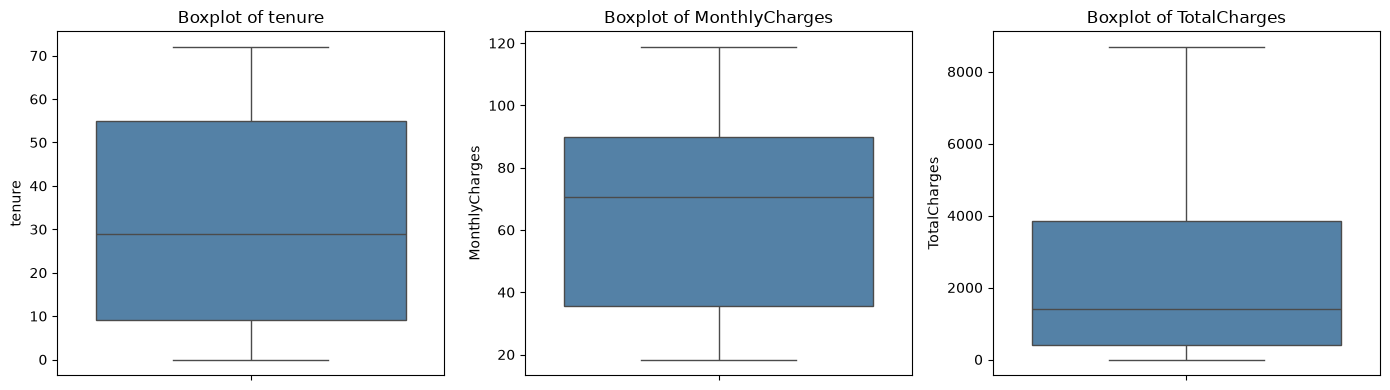

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(y=train_df[column], ax=axis, color="steelblue")
    axis.set_title(f"Boxplot of {column}")
    axis.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_boxplots.png", dpi=200)
plt.show()

### 5.3 Correlation between the numeric features

In [20]:
train_df[NUMERIC_FEATURES].corr().round(3)

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2570,0.8300
MonthlyCharges,0.2570,1.0000,0.6540
TotalCharges,0.8300,0.6540,1.0000


`TotalCharges` correlates strongly with `tenure` (0.83) and clearly with `MonthlyCharges` (0.65), as expected from the audit: it is roughly their product. This overlap is worth remembering later: strongly correlated features make regression coefficients harder to interpret.

### 5.4 Churn distribution

In [21]:
churn_summary = pd.DataFrame({
    "count": y_train.value_counts(),
    "percent": y_train.value_counts(normalize=True) * 100,
}).sort_index().rename(index={0: "No", 1: "Yes"})
churn_summary

,count,percent
Churn,,
No,4139,73.4647
Yes,1495,26.5353


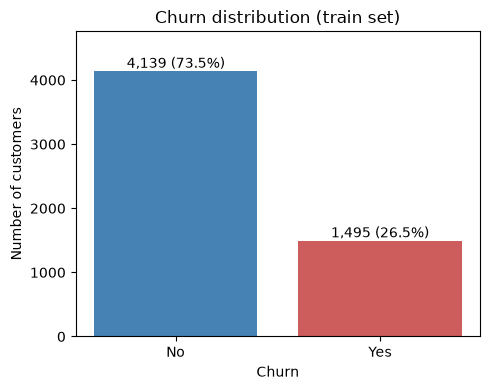

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(churn_summary.index, churn_summary["count"], color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{count:,} ({percent:.1f}%)" for count, percent in churn_summary.itertuples(index=False)])
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_title("Churn distribution (train set)")
ax.set_ylim(0, churn_summary["count"].max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_churn_distribution.png", dpi=200)
plt.show()

The train set has 4,139 non-churners (73.5%) and 1,495 churners (26.5%). With this imbalance a model that always predicts "No" already reaches about 73.5% accuracy while finding no churner, so accuracy alone is misleading and the baselines report recall and F1 for the churn class. It also justifies the stratified split in Section 4 and the later comparison of SMOTE against class weights.

### 5.5 Chi-square test and Cramér's V for the 16 categorical features

For each feature the test compares its distribution across churned and non-churned customers. Cramér's V rescales the Chi-square statistic to the range 0 to 1 so features with different numbers of categories can be ranked: $V = \sqrt{\chi^2 / (n \cdot \min(r-1, c-1))}$. The p-value uses the standard Chi-square test; V is computed from the uncorrected statistic (`correction=False`), the textbook definition.

In [23]:
def cramers_v(contingency_table):
    chi2_statistic = chi2_contingency(contingency_table, correction=False)[0]
    total_observations = contingency_table.to_numpy().sum()
    smaller_dimension = min(contingency_table.shape) - 1
    return np.sqrt(chi2_statistic / (total_observations * smaller_dimension))

In [24]:
association_rows = []
for feature in CATEGORICAL_FEATURES:
    contingency_table = pd.crosstab(train_df[feature], train_df[TARGET_COLUMN])
    chi2_statistic, p_value, degrees_of_freedom, _ = chi2_contingency(contingency_table)
    association_rows.append({
        "feature": feature,
        "chi2": chi2_statistic,
        "dof": degrees_of_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v(contingency_table),
        "significant": p_value < SIGNIFICANCE_LEVEL,
    })

association_table = (
    pd.DataFrame(association_rows)
    .sort_values("cramers_v", ascending=False)
    .reset_index(drop=True)
)
association_table.to_csv(ARTIFACTS_DIR / "eda_chi2_cramers_v.csv", index=False)
association_table

,feature,chi2,dof,p_value,cramers_v,significant
0,Contract,952.3080,2,0.0000,0.4111,True
1,InternetService,600.8466,2,0.0000,0.3266,True
2,PaymentMethod,545.2144,3,0.0000,0.3111,True
3,PaperlessBilling,219.9225,1,0.0000,0.1980,True
4,OnlineSecurity,170.8442,1,0.0000,0.1746,True
5,Dependents,157.1637,1,0.0000,0.1675,True
6,TechSupport,153.9081,1,0.0000,0.1657,True
7,Partner,118.9693,1,0.0000,0.1457,True
8,SeniorCitizen,118.5457,1,0.0000,0.1456,True
9,OnlineBackup,37.8896,1,0.0000,0.0824,True


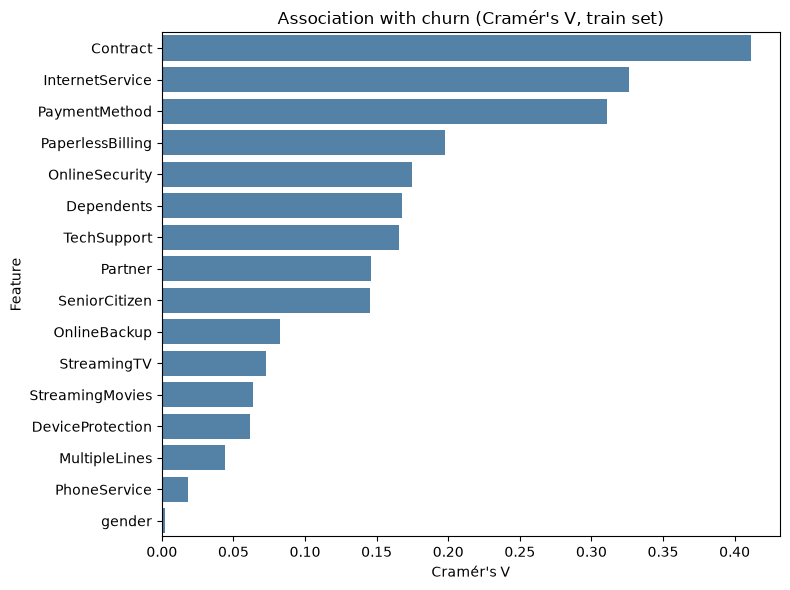

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=association_table, x="cramers_v", y="feature", color="steelblue", ax=ax)
ax.set_title("Association with churn (Cramér's V, train set)")
ax.set_xlabel("Cramér's V")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_cramers_v.png", dpi=200)
plt.show()

14 of the 16 categorical features are significantly associated with churn (p < 0.05). The strongest are `Contract` (V = 0.41), `InternetService` (V = 0.33) and `PaymentMethod` (V = 0.31), all moderate. `gender` (p = 0.892) and `PhoneService` (p = 0.195) show no significant association, which makes them candidates for removal in the feature-selection step. A small p-value does not mean a large effect: `MultipleLines` is significant but its V is only 0.04, so with 5,634 rows even a negligible association can pass the test. These are univariate associations, not causal effects.

In [26]:
# Cell 1: Import các thư viện bổ sung cho Section 2
from sklearn.preprocessing import FunctionTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [27]:

# Cell 2: Bước 2A - Domain Feature Engineering
def engineering_domain_features(X):
    """
    Tạo 3 đặc trưng nghiệp vụ mới (thực hiện sau khi chia Train/Test, nằm trong Pipeline)
    """
    X_out = X.copy()
    
    # 1. Total_Services_Count: Tổng số dịch vụ GTGT (từ 0 đến 6)
    # Tận dụng INTERNET_DEPENDENT_FEATURES đã định nghĩa ở Section 1
    X_out["Total_Services_Count"] = (X_out[INTERNET_DEPENDENT_FEATURES] == "Yes").sum(axis=1)
    
    # 2. Tenure_Cohort: Phân nhóm chu kỳ gắn bó
    bins = [-1, 12, 24, 48, np.inf]
    labels = ["0-12", "12-24", "24-48", ">48"]
    X_out["Tenure_Cohort"] = pd.cut(X_out["tenure"], bins=bins, labels=labels).astype(object)
    
    # 3. Charge_Ratio: Tỷ lệ cước hiện tại so với trung bình lịch sử
    # Cộng thêm 1e-5 để tránh chia cho 0
    avg_historical_charge = X_out["TotalCharges"] / (X_out["tenure"] + 1) + 1e-5
    X_out["Charge_Ratio"] = X_out["MonthlyCharges"] / avg_historical_charge
    
    return X_out

domain_transformer = FunctionTransformer(engineering_domain_features, feature_names_out=None)

In [28]:
# Cell 3: Bước 2B - Feature Selection (Loại bỏ biến nhiễu)
features_to_drop = ["gender", "PhoneService"]

# Cập nhật lại danh sách features (Thêm 3 biến mới, bớt 2 biến nhiễu)
UPDATED_CATEGORICAL = [col for col in CATEGORICAL_FEATURES if col not in features_to_drop] + ["Tenure_Cohort"]
UPDATED_NUMERIC = NUMERIC_FEATURES + ["Total_Services_Count", "Charge_Ratio"]


In [29]:

# Cell 4: Hàm tính VIF (Kiểm tra đa cộng tuyến)
def check_vif(df, features):
    """Tính VIF cho các biến số liên tục trên tập Train"""
    X_num = df[features].dropna()
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X_num.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X_num.values, i) 
        for i in range(len(X_num.columns))
    ]
    return vif_data.sort_values("VIF", ascending=False)

# Xem VIF trước khi xử lý (chỉ chạy trên tập Train)
train_engineered = engineering_domain_features(X_train)
print("VIF trên tập Train (Các biến số học):")
display(check_vif(train_engineered, UPDATED_NUMERIC))


VIF trên tập Train (Các biến số học):


,Feature,VIF
2,TotalCharges,10.3014
0,tenure,5.9370
1,MonthlyCharges,3.7479
3,Total_Services_Count,2.9047
4,Charge_Ratio,1.0065


In [30]:

# Cell 5: Thiết kế ColumnTransformer mới
preprocessor_yen = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), UPDATED_CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [ ]:
# CẬP NHẬT CELL 6: Dùng hàm thư viện đồng bộ cho cả 2 Pipeline
from sklearn.linear_model import LogisticRegression

# Pipeline 1: Tích hợp SMOTE (SMOTE đã lo việc cân bằng, nên mô hình để mặc định)
smote_pipeline = ImbPipeline([
    ("domain_features", domain_transformer),
    ("preprocess", preprocessor_yen),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)) 
])

# Pipeline 2: Đối chứng (Không dùng SMOTE, giao việc cân bằng cho class_weight)
balanced_pipeline = ImbPipeline([
    ("domain_features", domain_transformer),
    ("preprocess", preprocessor_yen),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)) 
])

# Test chạy thử qua Pipeline (Fit trên Train)
smote_pipeline.fit(X_train, y_train)
print("Pipeline (SMOTE) đã sẵn sàng. Số features sau tiền xử lý:", 
      len(smote_pipeline.named_steps["preprocess"].get_feature_names_out()))

1. Những gì Yến đã hoàn thành (Section 2)

Xây dựng bộ đặc trưng mới: Bạn đã tạo thành công 3 biến nghiệp vụ (Total_Services_Count, Tenure_Cohort, Charge_Ratio) và tự động hóa chúng vào Pipeline.   

Làm sạch và tối ưu biến: Đã loại bỏ thành công các biến nhiễu (gender, PhoneService) sau khi kiểm tra VIF.   

Thiết lập dây chuyền chống rò rỉ dữ liệu: Bạn đã đóng gói hoàn hảo các bước chuẩn hóa (StandardScaler), mã hóa (OneHotEncoder) và cân bằng dữ liệu (SMOTE) vào một ImbPipeline khép kín. Nhờ vậy, SMOTE sẽ chỉ sinh mẫu trên tập Train mà không bị tràn sang tập Test. Dây chuyền này giờ đã sẵn sàng để lắp mô hình vào chạy